# M05-2 | 校準：樣本數怎麼影響結果，校準時 BN 會動嗎

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m05_ptq_pipeline/02_calibration_study.ipynb)

校準資料決定每個 observer 看到的範圍，也就決定 scale。資料太少，範圍估不準。這本 notebook 用 M05-1 的輸出 SQNR 量兩件事：

- **A.** 校準樣本數與 SQNR：每個樣本數換 5 份不同的校準資料各做一次，看平均與**波動**。
- **B.** 校準時 BN 會不會影響結果。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m05_ptq_pipeline")

In [1]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, trained_tiny_net
from common.graph_utils import sqnr
from common.models import example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

模型與評估資料都和 M05-1 相同（`trained_tiny_net()`、`calibration_batches(64, seed=9)`）：

In [2]:
model = trained_tiny_net()
gm = export_module(model, example_inputs())
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
(x_eval,) = next(calibration_batches(64, seed=9))  # 固定的評估輸入，和所有校準資料都不同
with torch.no_grad():
    y_ref = model(x_eval)

## A. 校準樣本數與 SQNR

每個樣本數 $n$，用 5 個不同的 seed 產生 5 份校準資料，各做一次 prepare、校準、convert：

In [3]:
SEEDS = (1, 2, 3, 4, 5)
SIZES = (16, 32, 64, 128, 256, 512)

results = {}
for n in SIZES:
    results[n] = []
    for seed in SEEDS:
        prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
        with torch.no_grad():
            for batch in calibration_batches(n, seed=seed):
                prepared(*batch)
            results[n].append(sqnr(y_ref, convert_pt2e(prepared)(x_eval)))

mean = {n: sum(v) / len(v) for n, v in results.items()}
spread = {n: max(v) - min(v) for n, v in results.items()}

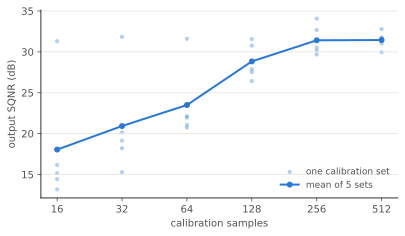

In [4]:
#| code-fold: true
#| code-summary: 畫圖的程式
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for i, (n, scores) in enumerate(results.items()):
    ax.scatter([n] * len(scores), scores, s=18, color=BLUE, alpha=0.35, linewidths=0,
               label="one calibration set" if i == 0 else None)
ax.plot(SIZES, [mean[n] for n in SIZES], color=BLUE, lw=2, marker="o", ms=5, label="mean of 5 sets")
ax.legend(loc="lower right", frameon=False, labelcolor=MUTED, fontsize=9)
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [str(n) for n in SIZES])
ax.set_xlabel("calibration samples", color=MUTED)
ax.set_ylabel("output SQNR (dB)", color=MUTED)
ax.grid(axis="y", color="#e6e5e1", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
plt.show()

In [5]:
table([[n, f"{mean[n]:.2f}", f"{min(results[n]):.2f} ~ {max(results[n]):.2f}", f"{spread[n]:.2f}"] for n in SIZES],
      ["校準樣本數", "平均", "min ~ max", "波動（max − min）"])

校準樣本數,平均,min ~ max,波動（max − min）
16,18.05,13.17 ~ 31.30,18.13
32,20.93,15.28 ~ 31.84,16.55
64,23.50,20.73 ~ 31.60,10.87
128,28.83,26.42 ~ 31.57,5.14
256,31.41,29.67 ~ 34.06,4.39
512,31.44,29.96 ~ 32.78,2.82


In [6]:
assert spread[SIZES[0]] > 2 * spread[SIZES[-1]]  # 樣本少時波動大得多
assert mean[SIZES[0]] < mean[SIZES[-1]]

圖上每個淺色點是一份校準資料的結果，深色線是 5 份的平均：

- 樣本少時，不只平均較低，更重要的是**換一份校準資料結果就差很多**。同一個模型、同一個設定，只因為校準資料不同，SQNR 可以差十幾 dB。
- 樣本多了，點才收攏。所以要看的是波動，不只是一次的結果：只跑一次、剛好抽到好的一份，會高估量化的品質。
- 這份合成資料同分布、很乾淨；真實資料需要多少樣本，取決於資料本身，這裡的數字不能直接套用。

實務上：樣本數加到波動收斂為止；懷疑量化品質時，先換幾份校準資料重跑，看結果穩不穩。

## B. 校準時 BN 會不會影響結果

M04-1 看過，`prepare_pt2e` 一開始就把 BN 折進 conv。所以校準時圖上已經沒有 BN：

In [7]:
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
n_bn = sum("batch_norm" in str(n.target) for n in prepared.graph.nodes)
print("prepare 之後的 batch_norm 數量：", n_bn)
assert n_bn == 0

prepare 之後的 batch_norm 數量： 0


這有什麼影響？比較同一筆樣本「單獨跑」和「和另外 15 筆同一個 batch 跑」的輸出。
對照組是原模型的 train 模式：BN 用當下 batch 的統計，輸出會隨同批的其他樣本改變。

In [8]:
(x,) = next(calibration_batches(16, seed=5))
bn_train = copy.deepcopy(model).train()
with torch.no_grad():
    alone = torch.cat([prepared(x[i : i + 1]) for i in range(len(x))])
    together = prepared(x)
    bn_alone = torch.cat([bn_train(x[i : i + 1]) for i in range(len(x))])
    bn_together = bn_train(x)
d_prepared = float((alone - together).abs().max())
d_bn = float((bn_alone - bn_together).abs().max())
table([["prepare 之後的圖（校準時用的）", f"{d_prepared:.2e}"], ["對照：原模型的 train 模式", f"{d_bn:.2e}"]],
      ["", "單獨跑 vs 和 15 筆同批：最大輸出差"])

,單獨跑 vs 和 15 筆同批：最大輸出差
prepare 之後的圖（校準時用的）,2.29e-05
對照：原模型的 train 模式,6.79e+00


In [9]:
assert d_prepared < 1e-3 < d_bn

- 校準用的圖裡，BN 已經是固定的乘加（用 running stats 折進 conv），這個模型也沒有其他跨 batch 的運算，所以輸出只取決於樣本自己，差別只有浮點誤差。
- 對照組的輸出隨同批樣本改變。如果校準時 BN 還這樣運作，observer 看到的範圍會跟著 batch 的組成漂移。PTQ 的圖沒有 BN，天生避開了這個問題（前提是 export 時用 eval 模式）。

所以 PTQ 校準時不必擔心 BN，對這個模型而言，校準的 batch size 只影響跑多快。QAT 才有 BN 統計的問題（M06）。

## 小結

- 校準樣本少時，結果隨校準資料大幅波動；要看波動，不是只看一次的結果。
- PTQ 校準用的圖沒有 BN，輸出不受 batch 組成影響。